In [2]:
import pandas as pd 
import seaborn as sns
import numpy as np 
import matplotlib.pyplot as plt 
import os 

In [3]:
files = os.listdir("uber-traffic")
files

['uber-raw-data-janjune-15.csv',
 'uber-raw-data-apr14.csv',
 'uber-raw-data-aug14.csv',
 'uber-raw-data-sep14.csv',
 'uber-raw-data-jul14.csv',
 'uber-raw-data-jun14.csv',
 'uber-raw-data-may14.csv']

In [4]:
files.remove("uber-raw-data-janjune-15.csv")
files

['uber-raw-data-apr14.csv',
 'uber-raw-data-aug14.csv',
 'uber-raw-data-sep14.csv',
 'uber-raw-data-jul14.csv',
 'uber-raw-data-jun14.csv',
 'uber-raw-data-may14.csv']

In [5]:
path = "/Applications/MAMP/htdocs/local/kodingakademi/Python/python 4/bootcamp batch 3/uber-traffic"

final = pd.DataFrame()

for file in files: # file  = uber-raw-data-apr14.csv
    df = pd.read_csv(path + "/" + file)
    final = pd.concat([df, final])

In [6]:
final.shape

(4534327, 4)

In [7]:
final.info()

<class 'pandas.core.frame.DataFrame'>
Index: 4534327 entries, 0 to 564515
Data columns (total 4 columns):
 #   Column     Dtype  
---  ------     -----  
 0   Date/Time  object 
 1   Lat        float64
 2   Lon        float64
 3   Base       object 
dtypes: float64(2), object(2)
memory usage: 173.0+ MB


In [8]:
df = final.copy()
df.head()

,Date/Time,Lat,Lon,Base
0,5/1/2014 0:02:00,40.7521,-73.9914,B02512
1,5/1/2014 0:06:00,40.6965,-73.9715,B02512
2,5/1/2014 0:15:00,40.7464,-73.9838,B02512
3,5/1/2014 0:17:00,40.7463,-74.0011,B02512
4,5/1/2014 0:17:00,40.7594,-73.9734,B02512


In [9]:
df["Date/Time"] = pd.to_datetime(df["Date/Time"], format = "%m/%d/%Y %H:%M:%S")

In [10]:
df["weekday"] = df["Date/Time"].dt.day_name()
df["day"] = df["Date/Time"].dt.day
df["minute"] = df["Date/Time"].dt.minute
df["month"] = df["Date/Time"].dt.month
df["hour"] = df["Date/Time"].dt.hour

df

,Date/Time,Lat,Lon,Base,weekday,day,minute,month,hour
0,2014-05-01 00:02:00,40.7521,-73.9914,B02512,Thursday,1,2,5,0
1,2014-05-01 00:06:00,40.6965,-73.9715,B02512,Thursday,1,6,5,0
2,2014-05-01 00:15:00,40.7464,-73.9838,B02512,Thursday,1,15,5,0
3,2014-05-01 00:17:00,40.7463,-74.0011,B02512,Thursday,1,17,5,0
4,2014-05-01 00:17:00,40.7594,-73.9734,B02512,Thursday,1,17,5,0
...,...,...,...,...,...,...,...,...,...
564511,2014-04-30 23:22:00,40.7640,-73.9744,B02764,Wednesday,30,22,4,23
564512,2014-04-30 23:26:00,40.7629,-73.9672,B02764,Wednesday,30,26,4,23
564513,2014-04-30 23:31:00,40.7443,-73.9889,B02764,Wednesday,30,31,4,23
564514,2014-04-30 23:32:00,40.6756,-73.9405,B02764,Wednesday,30,32,4,23


In [11]:
import plotly.express as px 

px.bar(x = df["weekday"].value_counts().index, 
       y = df["weekday"].value_counts().values)

(array([216928., 103517., 227152., 543565., 324851., 366329., 819491.,
        660869., 579117., 692508.]),
 array([ 0. ,  2.3,  4.6,  6.9,  9.2, 11.5, 13.8, 16.1, 18.4, 20.7, 23. ]),
 <BarContainer object of 10 artists>)

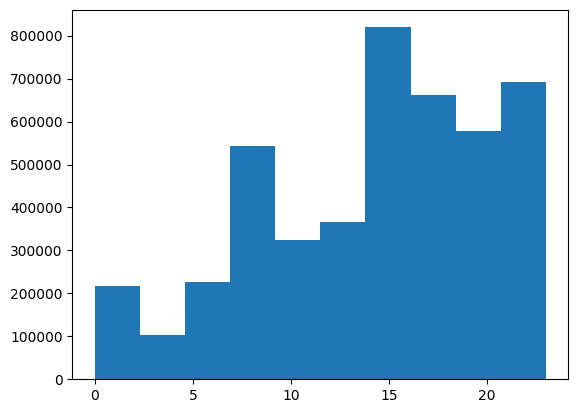

In [12]:
plt.hist(df["hour"])

In [13]:
df["month"].unique()

array([5, 6, 7, 9, 8, 4], dtype=int32)

In [14]:
for index, i in enumerate(df["month"].unique()):
    print(f"{index + 1}. {i}")

1. 5
2. 6
3. 7
4. 9
5. 8
6. 4


In [15]:
df.to_csv("uber_traffic.csv", index = False)